# Site magnetization vs time

Load the time-evolution magnetization data and plot $\langle S^z_i \rangle$ as a function of time for each site. Run this notebook from the repository root, or update `magz_path` below.

In [79]:
using DelimitedFiles
using Plots

magz_path = joinpath("results_compound", "time_evolution", "mag_z.csv")
data = readdlm(magz_path, ',', skipstart=1)

times = Float64.(data[:, 2])
sites = Int.(data[:, 3])
mag_z = Float64.(data[:, 4])

63936-element Vector{Float64}:
  0.006364130370912105
 -0.008898011122208149
 -0.0059184124164142135
  0.0065106763041602855
  0.005958291154911001
 -0.0048117328869291594
 -0.007654544869066952
  0.010063024188328999
  0.010804133930643604
 -0.010401191705222222
  ⋮
  0.008606443544415561
  0.006035166346801725
 -0.006066652029247396
 -0.007799050262380394
  0.011921847017940149
  0.00236273712102207
 -0.0014119390384187051
 -0.0029576451220161915
  0.0013312978249122162

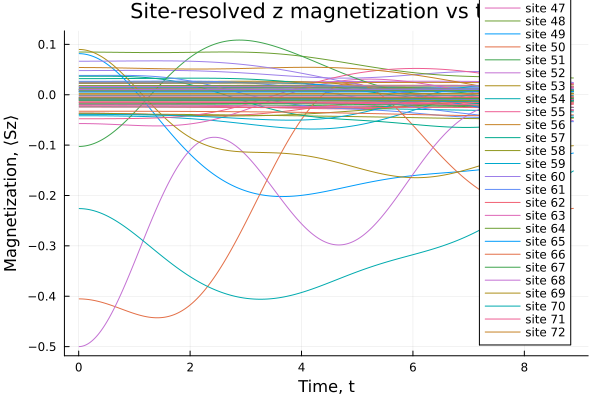

In [80]:
p = plot(
    xlabel="Time, t",
    ylabel="Magnetization, ⟨Sz⟩",
    title="Site-resolved z magnetization vs time",
    legend=:best,
)

for site in sort(unique(sites))
    indices = findall(==(site), sites)
    order = sortperm(times[indices])
    plot!(p, times[indices][order], mag_z[indices][order]; label="site $site")
end

display(p)

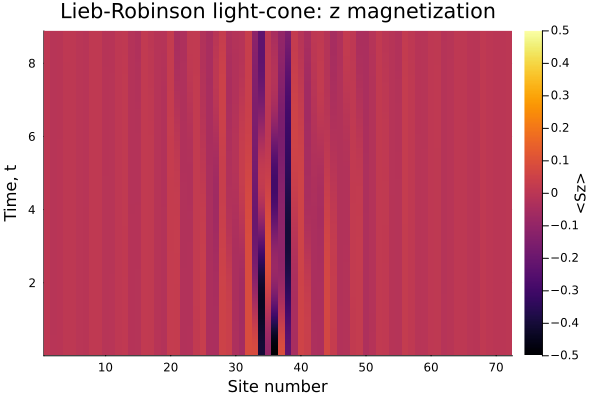

In [81]:
time_values = sort(unique(times))
site_values = sort(unique(sites))
mag_z_grid = fill(NaN, length(time_values), length(site_values))

for row in eachindex(mag_z)
    time_index = searchsortedfirst(time_values, times[row])
    site_index = searchsortedfirst(site_values, sites[row])
    mag_z_grid[time_index, site_index] = mag_z[row]
end

heatmap(
    site_values,
    time_values,
    mag_z_grid;
    xlabel="Site number",
    ylabel="Time, t",
    title="Lieb-Robinson light-cone: z magnetization",
    colorbar_title="<Sz>",
    clims=(-0.5, 0.5),
    interpolate=false,
)